In [1]:
import sys
import importlib.util
from pathlib import Path

def find_project_root(start_path=None):
    if start_path is None:
        start_path = Path.cwd()
    else:
        start_path = Path(start_path)

    current = start_path.resolve()

    while True:
        if (current / "09_config.py").exists() and (current / "08_utils.py").exists():
            return current
        if current.parent == current:
            raise FileNotFoundError("Project root tidak ditemukan.")
        current = current.parent

def import_py_file(module_name, file_path):
    file_path = Path(file_path).resolve()
    spec = importlib.util.spec_from_file_location(module_name, file_path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module
    spec.loader.exec_module(module)
    return module

PROJECT_ROOT = find_project_root()
cfg = import_py_file("ferplus_config", PROJECT_ROOT / "09_config.py")
utils = import_py_file("ferplus_utils", PROJECT_ROOT / "08_utils.py")

utils.set_global_seed(cfg.SEED)
utils.ensure_directories()

print("Grad-CAM menggunakan gambar dari test set yang sama.")

TensorFlow op determinism: ENABLED
Grad-CAM menggunakan gambar dari test set yang sama.


In [2]:
import tensorflow as tf

loaded_models = {}

for model_label, model_path in cfg.MODEL_PATHS.items():
    print("Loading:", model_label)
    print("Path:", model_path)

    model = tf.keras.models.load_model(model_path)
    loaded_models[model_label] = model

    last_conv_name = utils.find_last_conv_layer_name_in_efficientnet(model)
    print("Last Conv2D layer EfficientNetB0:", last_conv_name)
    print("-" * 80)

Loading: Model 1 - Baseline No Augmentation
Path: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_1_baseline_no_augmentation_best.keras
Last Conv2D layer EfficientNetB0: top_conv
--------------------------------------------------------------------------------
Loading: Model 2 - Training Full + Augmentation
Path: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_2_training_full_with_augmentation_best.keras
Last Conv2D layer EfficientNetB0: top_conv
--------------------------------------------------------------------------------
Loading: Model 3 - Training Full + Augmentation + Fine Tuning
Path: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_3_training_full_augmentation_finetuning_best.keras
Last Conv2D layer EfficientNetB0: top_conv
--------------------------------------------------------------------------------


In [3]:
import pandas as pd

prediction_files = {}

for model_label in cfg.MODEL_PATHS.keys():
    safe_name = (
        model_label
        .lower()
        .replace(" ", "_")
        .replace("-", "")
        .replace("+", "plus")
    )

    pred_path = cfg.RESULT_DIR / f"test_predictions_{safe_name}.csv"

    print(model_label)
    print(pred_path)
    print("Exists:", pred_path.exists())

    if pred_path.exists():
        prediction_files[model_label] = pd.read_csv(pred_path)

print("Jumlah file prediksi terbaca:", len(prediction_files))

Model 1 - Baseline No Augmentation
C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\test_predictions_model_1__baseline_no_augmentation.csv
Exists: True
Model 2 - Training Full + Augmentation
C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\test_predictions_model_2__training_full_plus_augmentation.csv
Exists: True
Model 3 - Training Full + Augmentation + Fine Tuning
C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\test_predictions_model_3__training_full_plus_augmentation_plus_fine_tuning.csv
Exists: True
Jumlah file prediksi terbaca: 3


In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

def run_gradcam_comparison(image_path, true_class):
    image_path = Path(image_path)

    if not image_path.exists():
        raise FileNotFoundError(f"Gambar tidak ditemukan: {image_path}")

    img_array = utils.load_image_as_array(image_path)
    original_img = Image.open(image_path).convert("RGB").resize(cfg.IMAGE_SIZE)

    image_safe_name = image_path.stem.replace(" ", "_")
    class_safe_name = str(true_class).replace(" ", "_")

    combined_path = cfg.GRADCAM_DIR / f"gradcam_comparison_{class_safe_name}_{image_safe_name}.png"

    plt.figure(figsize=(18, 5))

    plt.subplot(1, 4, 1)
    plt.imshow(original_img)
    plt.title(f"Original\nTrue: {true_class}")
    plt.axis("off")

    rows = []
    plot_index = 2

    for model_label, model in loaded_models.items():
        heatmap, pred_index, probs, used_conv_layer = utils.make_gradcam_heatmap(
            img_array=img_array,
            model=model,
            pred_index=None,
            last_conv_layer_name=None
        )

        pred_class = cfg.CLASS_NAMES[pred_index]
        confidence = float(probs[pred_index])

        overlay_bgr = utils.make_gradcam_overlay(
            image_path=image_path,
            heatmap=heatmap,
            alpha=0.4
        )

        overlay_rgb = cv2.cvtColor(overlay_bgr, cv2.COLOR_BGR2RGB)

        plt.subplot(1, 4, plot_index)
        plt.imshow(overlay_rgb)
        plt.title(
            f"{model_label}\n"
            f"Pred: {pred_class} ({confidence:.2f})\n"
            f"Layer: {used_conv_layer}"
        )
        plt.axis("off")

        rows.append({
            "image_path": str(image_path),
            "true_class": true_class,
            "model": model_label,
            "predicted_class": pred_class,
            "confidence": confidence,
            "used_conv_layer": used_conv_layer,
            "gradcam_combined_path": str(combined_path)
        })

        plot_index += 1

    plt.tight_layout()

    plt.savefig(combined_path, dpi=300)
    plt.show()

    print("Grad-CAM gabungan disimpan ke:", combined_path)

    return pd.DataFrame(rows)


Grad-CAM kelas: angry
Image: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\test\angry\fer0032225.png


c:\Users\Davin\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\models\functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_image']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


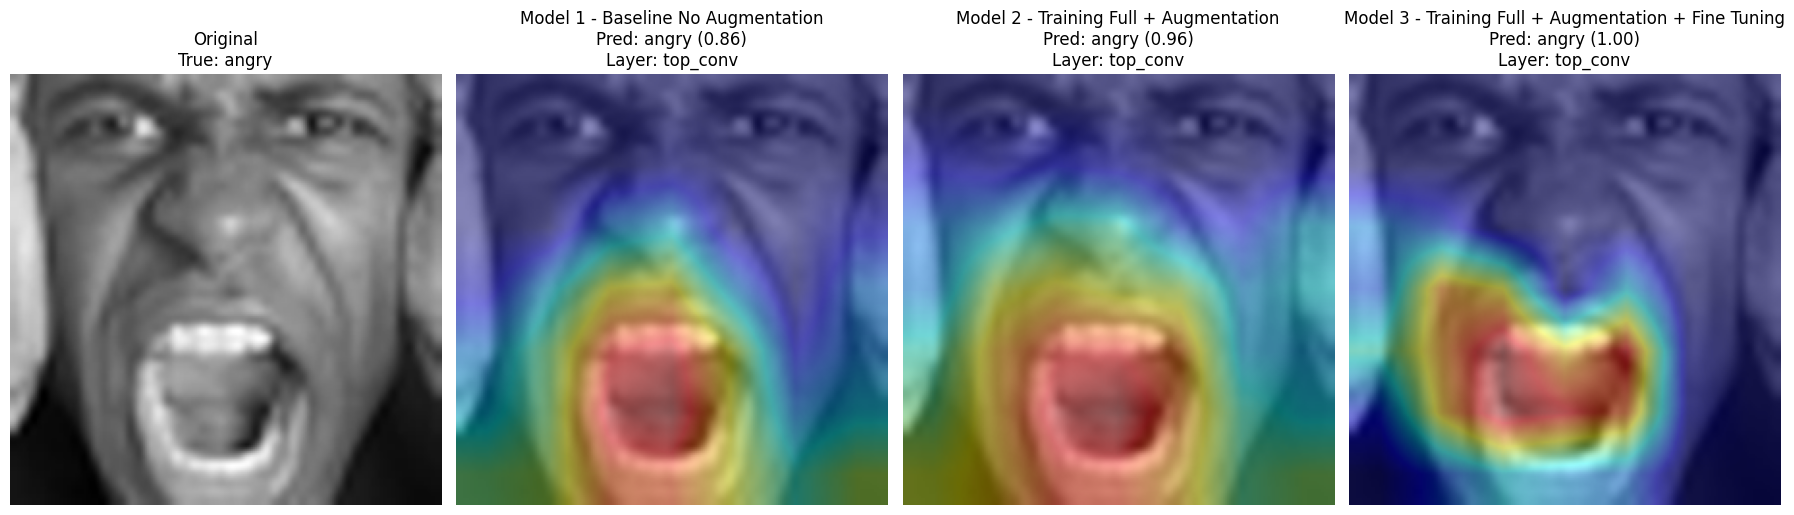

Grad-CAM gabungan disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\gradcam\gradcam_comparison_angry_fer0032225.png

Grad-CAM kelas: contempt
Image: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\test\contempt\fer0032220.png


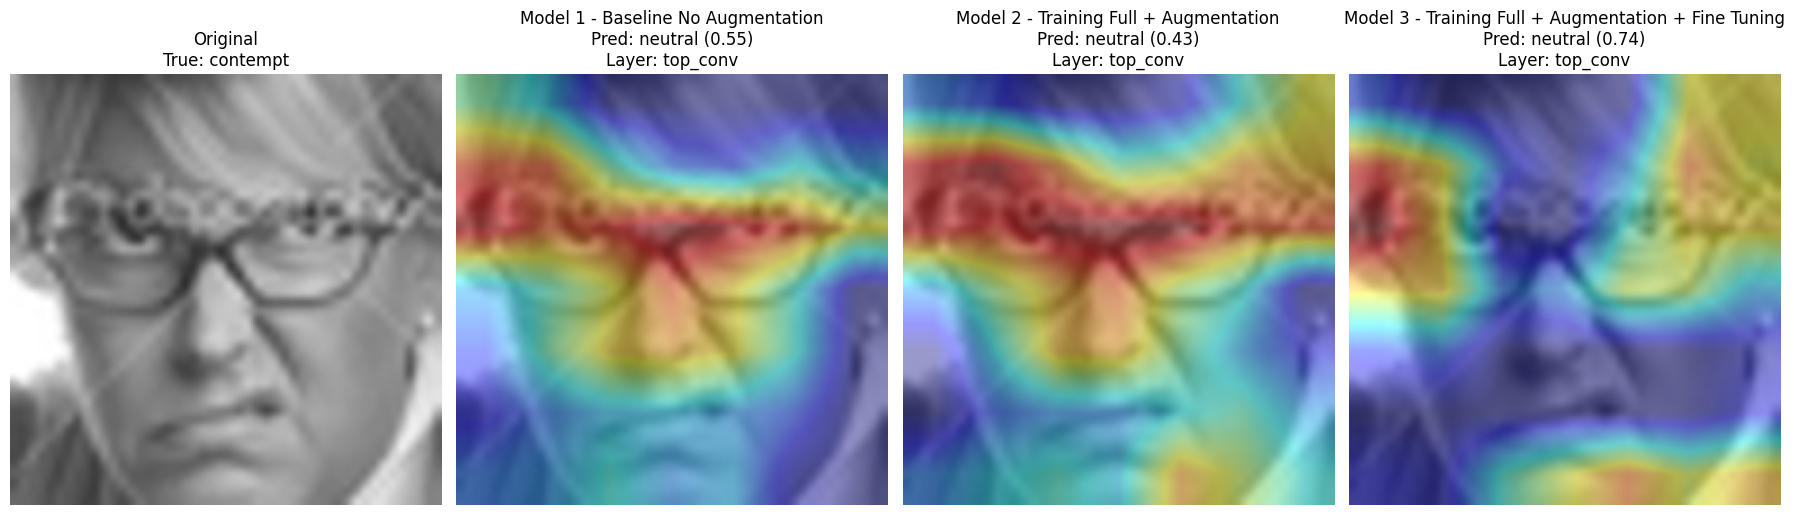

Grad-CAM gabungan disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\gradcam\gradcam_comparison_contempt_fer0032220.png

Grad-CAM kelas: disgust
Image: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\test\disgust\fer0032254.png


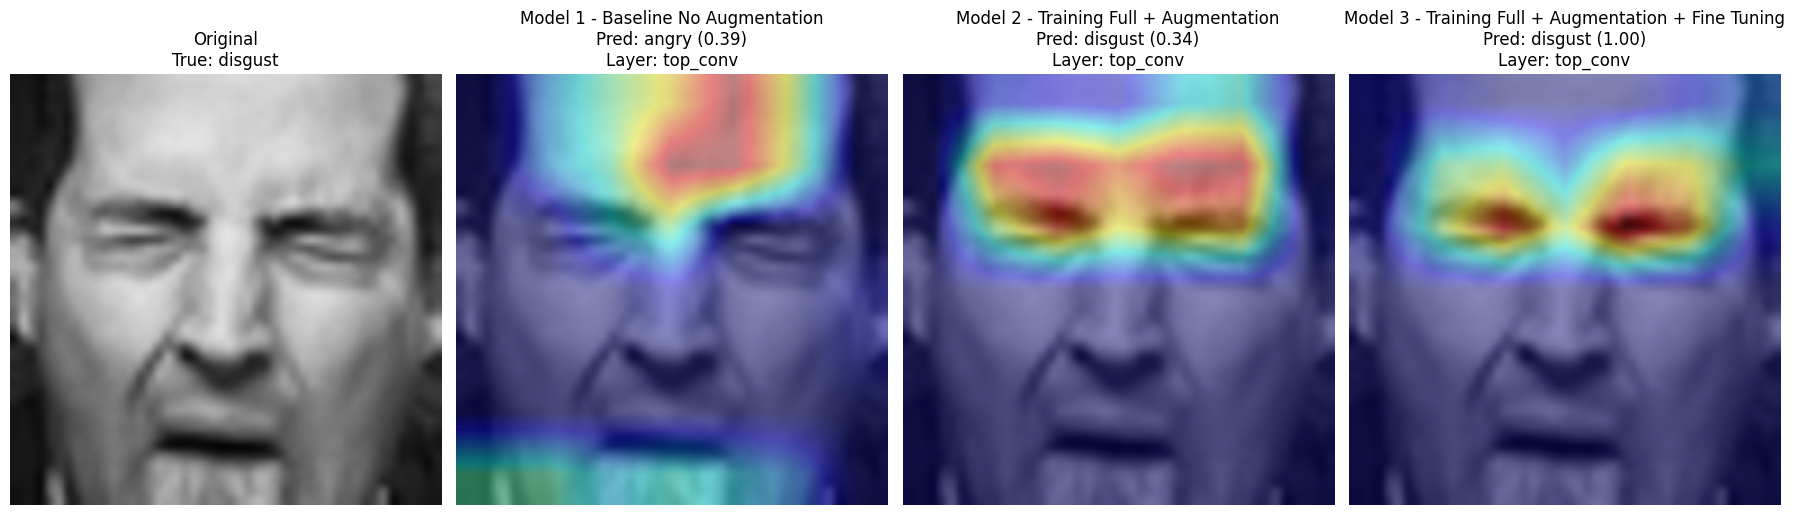

Grad-CAM gabungan disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\gradcam\gradcam_comparison_disgust_fer0032254.png

Grad-CAM kelas: fear
Image: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\test\fear\fer0032271.png


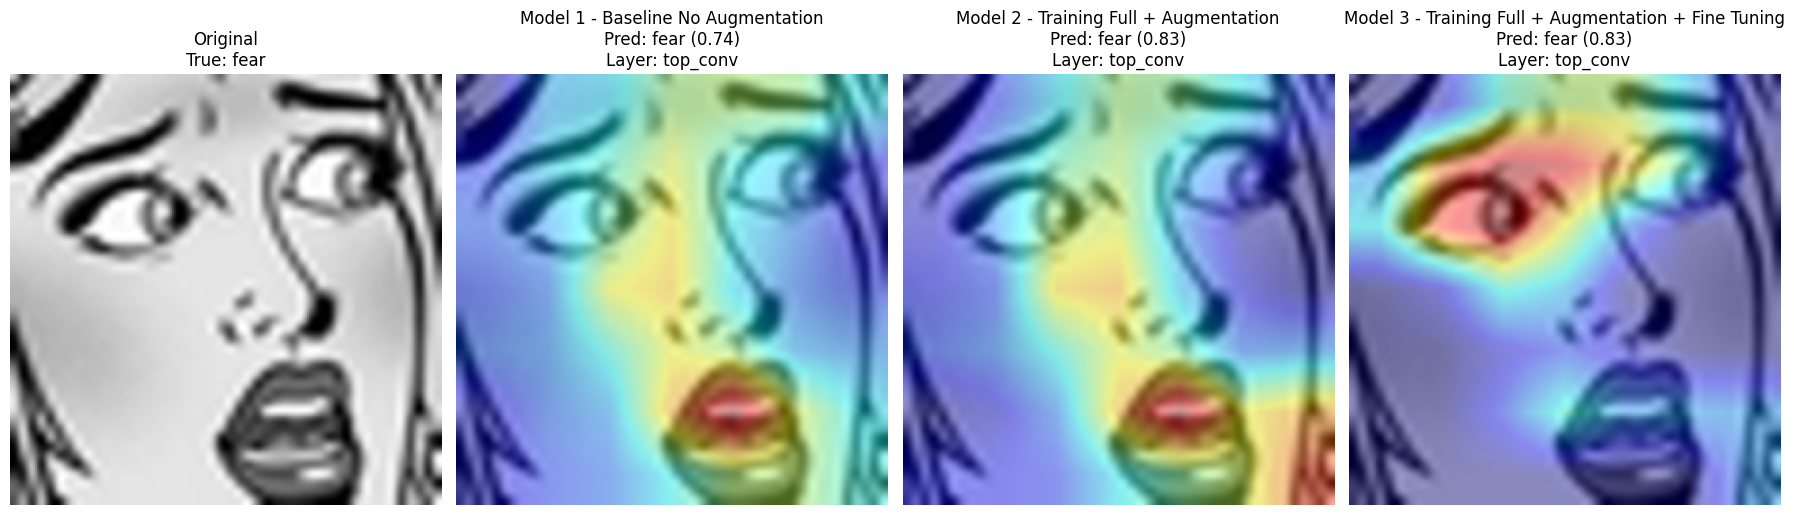

Grad-CAM gabungan disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\gradcam\gradcam_comparison_fear_fer0032271.png

Grad-CAM kelas: happy
Image: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\test\happy\fer0032227.png


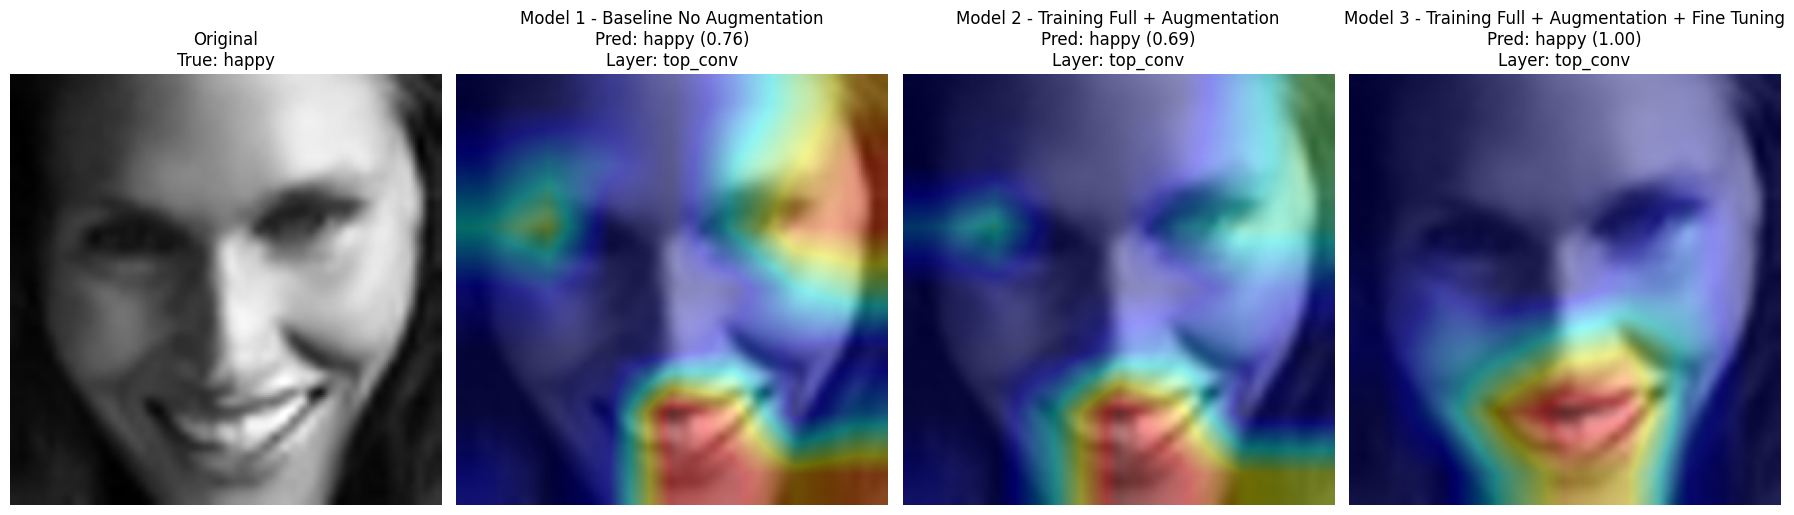

Grad-CAM gabungan disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\gradcam\gradcam_comparison_happy_fer0032227.png

Grad-CAM kelas: neutral
Image: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\test\neutral\fer0032223.png


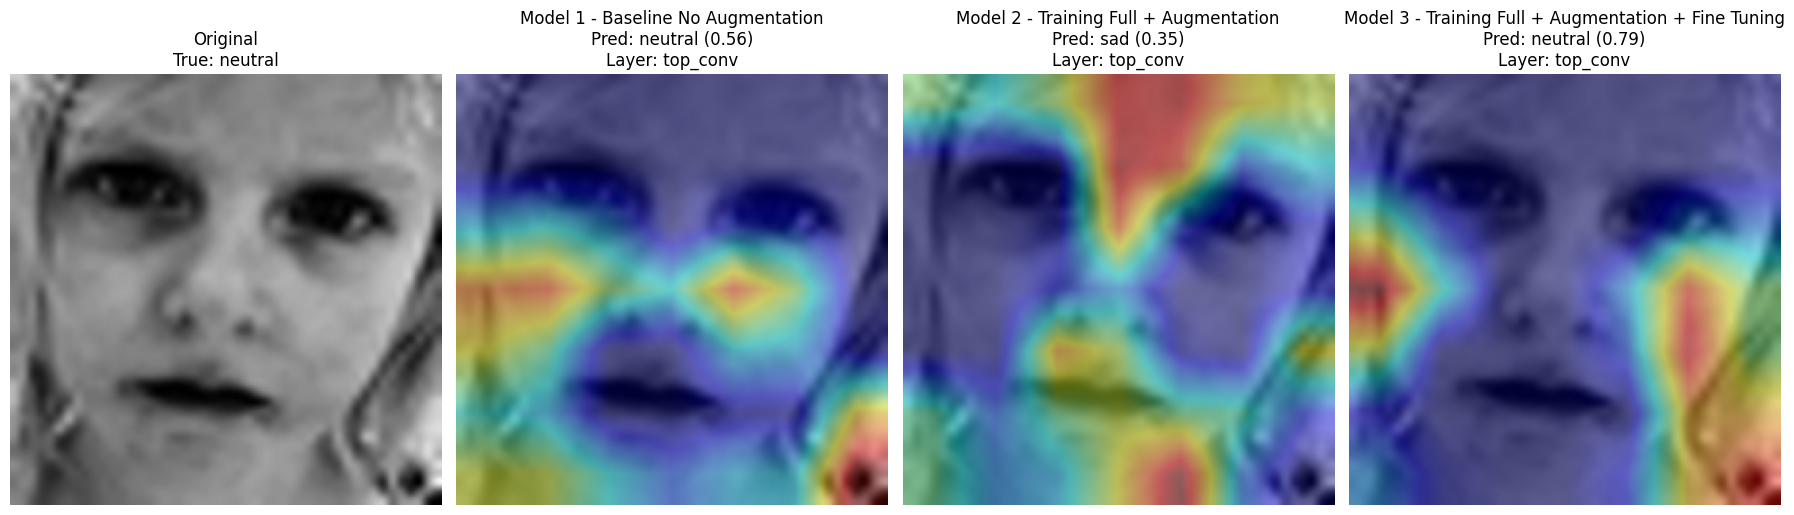

Grad-CAM gabungan disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\gradcam\gradcam_comparison_neutral_fer0032223.png

Grad-CAM kelas: sad
Image: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\test\sad\fer0032222.png


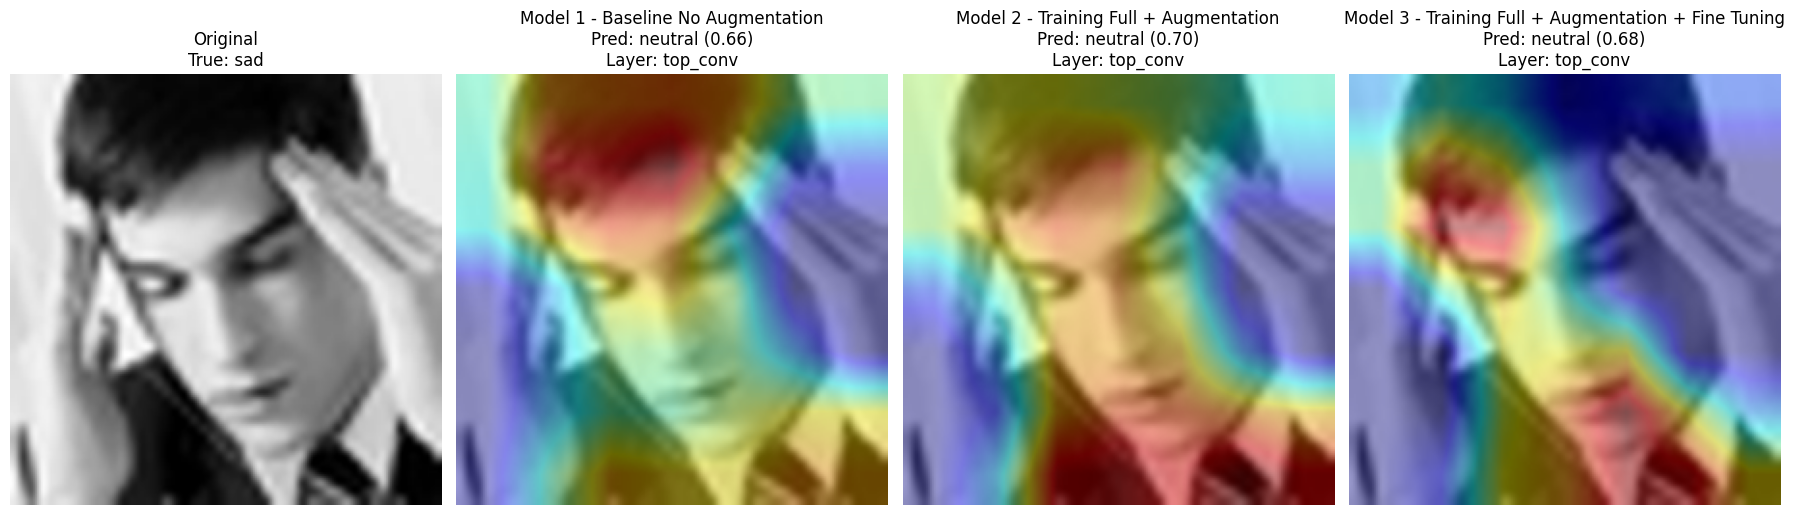

Grad-CAM gabungan disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\gradcam\gradcam_comparison_sad_fer0032222.png

Grad-CAM kelas: surprise
Image: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\test\surprise\fer0032224.png


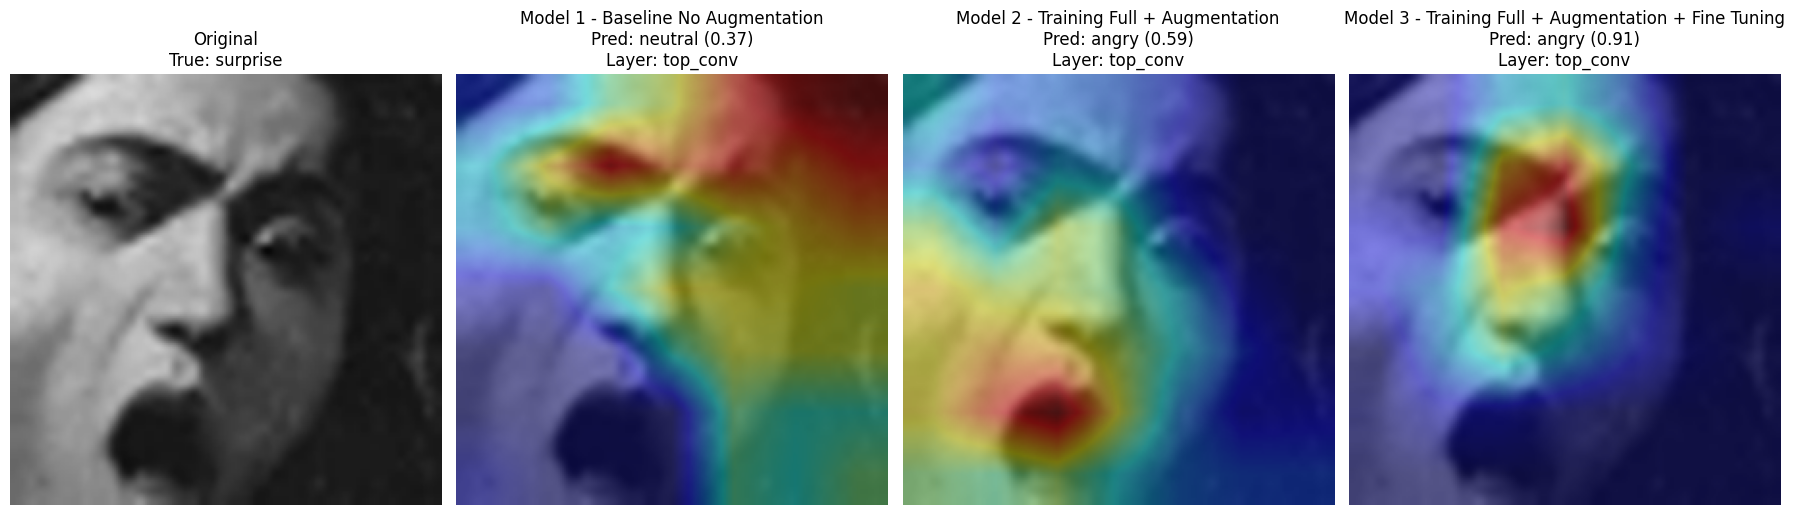

Grad-CAM gabungan disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\gradcam\gradcam_comparison_surprise_fer0032224.png


,image_path,true_class,model,predicted_class,confidence,used_conv_layer,gradcam_combined_path
0,C:\Users\Davin\Downloads\Skripsi\project_skrip...,angry,Model 1 - Baseline No Augmentation,angry,0.859093,top_conv,C:\Users\Davin\Downloads\Skripsi\project_skrip...
1,C:\Users\Davin\Downloads\Skripsi\project_skrip...,angry,Model 2 - Training Full + Augmentation,angry,0.956790,top_conv,C:\Users\Davin\Downloads\Skripsi\project_skrip...
2,C:\Users\Davin\Downloads\Skripsi\project_skrip...,angry,Model 3 - Training Full + Augmentation + Fine ...,angry,0.996121,top_conv,C:\Users\Davin\Downloads\Skripsi\project_skrip...
3,C:\Users\Davin\Downloads\Skripsi\project_skrip...,contempt,Model 1 - Baseline No Augmentation,neutral,0.550201,top_conv,C:\Users\Davin\Downloads\Skripsi\project_skrip...
4,C:\Users\Davin\Downloads\Skripsi\project_skrip...,contempt,Model 2 - Training Full + Augmentation,neutral,0.432003,top_conv,C:\Users\Davin\Downloads\Skripsi\project_skrip...
5,C:\Users\Davin\Downloads\Skripsi\project_skrip...,contempt,Model 3 - Training Full + Augmentation + Fine ...,neutral,0.744005,top_conv,C:\Users\Davin\Downloads\Skripsi\project_skrip...
6,C:\Users\Davin\Downloads\Skripsi\project_skrip...,disgust,Model 1 - Baseline No Augmentation,angry,0.387878,top_conv,C:\Users\Davin\Downloads\Skripsi\project_skrip...
7,C:\Users\Davin\Downloads\Skripsi\project_skrip...,disgust,Model 2 - Training Full + Augmentation,disgust,0.338568,top_conv,C:\Users\Davin\Downloads\Skripsi\project_skrip...
8,C:\Users\Davin\Downloads\Skripsi\project_skrip...,disgust,Model 3 - Training Full + Augmentation + Fine ...,disgust,0.997424,top_conv,C:\Users\Davin\Downloads\Skripsi\project_skrip...
9,C:\Users\Davin\Downloads\Skripsi\project_skrip...,fear,Model 1 - Baseline No Augmentation,fear,0.737786,top_conv,C:\Users\Davin\Downloads\Skripsi\project_skrip...


Ringkasan Grad-CAM per kelas disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\gradcam\gradcam_one_sample_per_class_summary.csv


In [5]:
all_gradcam_results = []

for class_name in cfg.CLASS_NAMES:
    class_dir = cfg.TEST_DIR / class_name
    image_files = utils.list_image_files(class_dir)

    if len(image_files) == 0:
        print("Tidak ada gambar untuk kelas:", class_name)
        continue

    image_path = image_files[0]

    print("\n" + "=" * 80)
    print("Grad-CAM kelas:", class_name)
    print("Image:", image_path)

    result_df = run_gradcam_comparison(
        image_path=image_path,
        true_class=class_name
    )

    all_gradcam_results.append(result_df)

gradcam_one_per_class_df = pd.concat(all_gradcam_results, ignore_index=True)

save_path = cfg.GRADCAM_DIR / "gradcam_one_sample_per_class_summary.csv"
gradcam_one_per_class_df.to_csv(save_path, index=False)

display(gradcam_one_per_class_df)
print("Ringkasan Grad-CAM per kelas disimpan ke:", save_path)

CSV Model 1: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\test_predictions_model_1__baseline_no_augmentation.csv
CSV Model 2: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\test_predictions_model_2__training_full_plus_augmentation.csv
CSV Model 3: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\test_predictions_model_3__training_full_plus_augmentation_plus_fine_tuning.csv
Jumlah data test yang berhasil dicocokkan: 3573

KASUS TERPILIH
Prioritas 1: Prediksi ketiga model berbeda dan Model 3 benar.
Image path : C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\test\angry\fer0032273.png
True label : angry
Pred Model 1: happy
Pred Model 2: disgust
Pred Model 3: angry


,case_note,image_path,true_label,pred_model_1,pred_model_2,pred_model_3,model_3_correct,all_three_predictions_different
0,Prioritas 1: Prediksi ketiga model berbeda dan...,C:\Users\Davin\Downloads\Skripsi\project_skrip...,angry,happy,disgust,angry,True,True


Ringkasan kasus terpilih disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\gradcam\gradcam_selected_different_prediction_case_summary.csv


c:\Users\Davin\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\models\functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_image']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


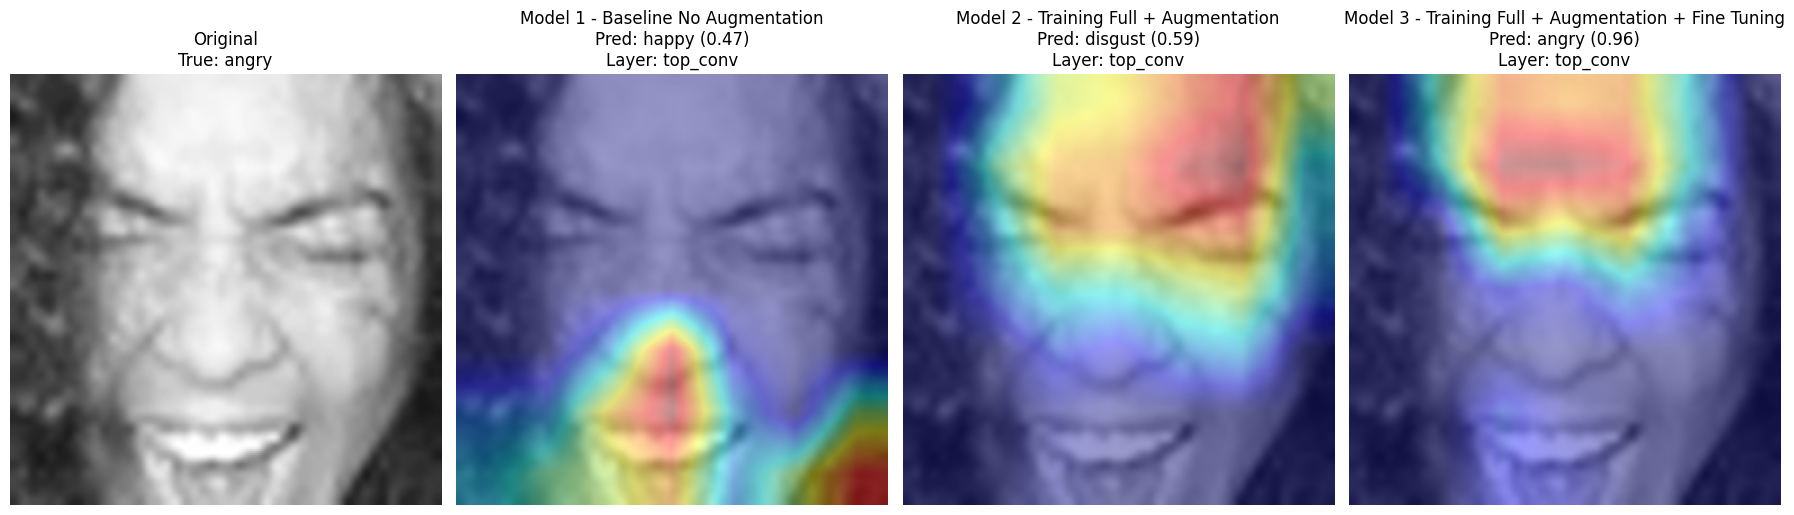

Grad-CAM gabungan disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\gradcam\gradcam_comparison_angry_fer0032273.png


,image_path,true_class,model,predicted_class,confidence,used_conv_layer,gradcam_combined_path
0,C:\Users\Davin\Downloads\Skripsi\project_skrip...,angry,Model 1 - Baseline No Augmentation,happy,0.465270,top_conv,C:\Users\Davin\Downloads\Skripsi\project_skrip...
1,C:\Users\Davin\Downloads\Skripsi\project_skrip...,angry,Model 2 - Training Full + Augmentation,disgust,0.594259,top_conv,C:\Users\Davin\Downloads\Skripsi\project_skrip...
2,C:\Users\Davin\Downloads\Skripsi\project_skrip...,angry,Model 3 - Training Full + Augmentation + Fine ...,angry,0.962637,top_conv,C:\Users\Davin\Downloads\Skripsi\project_skrip...


Hasil Grad-CAM kasus terpilih disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\gradcam\gradcam_selected_different_prediction_case_result.csv


In [6]:
from pathlib import Path
import pandas as pd
import numpy as np


def normalize_path_for_merge(path_value):
    return str(Path(path_value)).replace("\\", "/").lower()


def find_prediction_csv_for_model(model_number):

    csv_files = list(cfg.RESULT_DIR.glob("*.csv"))

    candidates = []

    for csv_path in csv_files:
        name = csv_path.name.lower()

        is_prediction_file = (
            "prediction" in name
            or "predictions" in name
            or "prediksi" in name
        )

        is_model_file = (
            f"model_{model_number}" in name
            or f"model-{model_number}" in name
            or f"model {model_number}" in name
            or f"model{model_number}" in name
        )

        if is_prediction_file and is_model_file:
            candidates.append(csv_path)

    if len(candidates) == 0:
        raise FileNotFoundError(
            f"Tidak ditemukan CSV prediksi untuk Model {model_number} di folder: {cfg.RESULT_DIR}\n"
            f"Pastikan notebook 05_evaluasi_perbandingan_model.ipynb sudah dijalankan."
        )

    candidates = sorted(candidates, key=lambda p: p.stat().st_mtime, reverse=True)

    return candidates[0]


model_1_csv = find_prediction_csv_for_model(1)
model_2_csv = find_prediction_csv_for_model(2)
model_3_csv = find_prediction_csv_for_model(3)

print("CSV Model 1:", model_1_csv)
print("CSV Model 2:", model_2_csv)
print("CSV Model 3:", model_3_csv)

df_m1 = pd.read_csv(model_1_csv)
df_m2 = pd.read_csv(model_2_csv)
df_m3 = pd.read_csv(model_3_csv)


required_columns = ["file_path", "true_label_name", "pred_label_name"]

for df_name, df in [
    ("Model 1", df_m1),
    ("Model 2", df_m2),
    ("Model 3", df_m3)
]:
    missing_cols = [col for col in required_columns if col not in df.columns]

    if missing_cols:
        raise ValueError(
            f"{df_name} tidak memiliki kolom wajib: {missing_cols}\n"
            f"Kolom yang tersedia: {list(df.columns)}"
        )


df_m1 = df_m1.copy()
df_m2 = df_m2.copy()
df_m3 = df_m3.copy()

df_m1["merge_key"] = df_m1["file_path"].apply(normalize_path_for_merge)
df_m2["merge_key"] = df_m2["file_path"].apply(normalize_path_for_merge)
df_m3["merge_key"] = df_m3["file_path"].apply(normalize_path_for_merge)

m1_small = df_m1[["merge_key", "file_path", "true_label_name", "pred_label_name"]].rename(
    columns={
        "file_path": "file_path_m1",
        "true_label_name": "true_label",
        "pred_label_name": "pred_model_1"
    }
)

m2_small = df_m2[["merge_key", "pred_label_name"]].rename(
    columns={
        "pred_label_name": "pred_model_2"
    }
)

m3_small = df_m3[["merge_key", "pred_label_name"]].rename(
    columns={
        "pred_label_name": "pred_model_3"
    }
)

merged_df = (
    m1_small
    .merge(m2_small, on="merge_key", how="inner")
    .merge(m3_small, on="merge_key", how="inner")
)

print("Jumlah data test yang berhasil dicocokkan:", len(merged_df))


all_three_different = (
    (merged_df["pred_model_1"] != merged_df["pred_model_2"]) &
    (merged_df["pred_model_1"] != merged_df["pred_model_3"]) &
    (merged_df["pred_model_2"] != merged_df["pred_model_3"])
)

model_3_correct = merged_df["pred_model_3"] == merged_df["true_label"]

any_disagreement = (
    (merged_df["pred_model_1"] != merged_df["pred_model_2"]) |
    (merged_df["pred_model_1"] != merged_df["pred_model_3"]) |
    (merged_df["pred_model_2"] != merged_df["pred_model_3"])
)

candidate_priority_1 = merged_df[all_three_different & model_3_correct].copy()
candidate_priority_2 = merged_df[any_disagreement & model_3_correct].copy()
candidate_priority_3 = merged_df[all_three_different].copy()
candidate_priority_4 = merged_df[any_disagreement].copy()

if len(candidate_priority_1) > 0:
    selected_df = candidate_priority_1
    selected_case_note = "Prioritas 1: Prediksi ketiga model berbeda dan Model 3 benar."

elif len(candidate_priority_2) > 0:
    selected_df = candidate_priority_2
    selected_case_note = "Prioritas 2: Ada perbedaan prediksi antar model dan Model 3 benar."

elif len(candidate_priority_3) > 0:
    selected_df = candidate_priority_3
    selected_case_note = "Prioritas 3: Prediksi ketiga model berbeda, tetapi Model 3 belum tentu benar."

elif len(candidate_priority_4) > 0:
    selected_df = candidate_priority_4
    selected_case_note = "Prioritas 4: Ada perbedaan prediksi antar model, tetapi Model 3 belum tentu benar."

else:
    raise ValueError(
        "Tidak ditemukan contoh gambar test dengan prediksi antar model yang berbeda."
    )

selected_row = selected_df.iloc[0]

selected_image_path = Path(selected_row["file_path_m1"])
true_class = selected_row["true_label"]

if not selected_image_path.exists():
    selected_image_path = cfg.TEST_DIR / true_class / Path(selected_row["file_path_m1"]).name

if not selected_image_path.exists():
    raise FileNotFoundError(
        f"File gambar tidak ditemukan:\n{selected_row['file_path_m1']}\n"
        f"Juga tidak ditemukan di:\n{selected_image_path}"
    )



print("\n" + "=" * 80)
print("KASUS TERPILIH")
print("=" * 80)
print(selected_case_note)
print("Image path :", selected_image_path)
print("True label :", true_class)
print("Pred Model 1:", selected_row["pred_model_1"])
print("Pred Model 2:", selected_row["pred_model_2"])
print("Pred Model 3:", selected_row["pred_model_3"])

selected_summary_df = pd.DataFrame([{
    "case_note": selected_case_note,
    "image_path": str(selected_image_path),
    "true_label": true_class,
    "pred_model_1": selected_row["pred_model_1"],
    "pred_model_2": selected_row["pred_model_2"],
    "pred_model_3": selected_row["pred_model_3"],
    "model_3_correct": selected_row["pred_model_3"] == true_class,
    "all_three_predictions_different": (
        selected_row["pred_model_1"] != selected_row["pred_model_2"]
        and selected_row["pred_model_1"] != selected_row["pred_model_3"]
        and selected_row["pred_model_2"] != selected_row["pred_model_3"]
    )
}])

display(selected_summary_df)

summary_save_path = cfg.GRADCAM_DIR / "gradcam_selected_different_prediction_case_summary.csv"
selected_summary_df.to_csv(summary_save_path, index=False)

print("Ringkasan kasus terpilih disimpan ke:", summary_save_path)


selected_gradcam_result_df = run_gradcam_comparison(
    image_path=selected_image_path,
    true_class=true_class
)

selected_gradcam_save_path = cfg.GRADCAM_DIR / "gradcam_selected_different_prediction_case_result.csv"
selected_gradcam_result_df.to_csv(selected_gradcam_save_path, index=False)

display(selected_gradcam_result_df)

print("Hasil Grad-CAM kasus terpilih disimpan ke:", selected_gradcam_save_path)